# Unit 8 Gradient Cost Function
This notebook runs the supplied tutorial, gradient_descent_cost_function.ipynb, then changes the number of iterations and the learning rate to see how the cost decreases, as the brief asks. I ran it in Google Colab.

## Scope and corrections
The original notebook is unchanged; I worked on a copy, keeping its text and diagram. I corrected one error and made one change so that the experiments could run. The error: each line it printed paired the slope and intercept after an update with the cost from before that update; each line now shows the cost of the slope and intercept printed beside it. The change: the number of iterations and the learning rate were fixed inside the function, so they are now arguments, with the supplied values (100 and 0.08) as defaults, and the function returns the slope, intercept and cost at every step so that runs can be compared and plotted. I also removed an empty code cell at the end.

After the supplied run I add four checks of my own: a grid of iterations and learning rates, the point where the learning rate becomes too large, the effect of scaling the input, and a changed dataset that no straight line fits exactly.

In [1]:
from datetime import datetime, timezone
print("Run by Anne Dayer (student 39359) in Google Colab on",
      datetime.now(timezone.utc).strftime("%d %B %Y at %H:%M UTC"))

Run by Anne Dayer (student 39359) in Google Colab on 03 November 2026 at 10:35 UTC


In [2]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
OUT = Path.cwd() / 'Unit8_ePortfolio_Exports'
OUT.mkdir(exist_ok=True)
def save_figure(name):
    plt.gcf().savefig(OUT / name, dpi=180, bbox_inches='tight')
versions = {'numpy': np.__version__, 'pandas': pd.__version__, 'matplotlib': matplotlib.__version__}
print('Package versions:', versions)

Package versions: {'numpy': '2.4.6', 'pandas': '2.2.3', 'matplotlib': '3.10.0'}


## Part 1: the supplied tutorial (corrected)

## Calculating cost with gradient descent and learning rate
- Change the iteration and learning rate vaules and see the impact on cost.
- Low iteration values with high learning rate (i.e. big steps) may lead to miss the global minimum
- Goal is to reach minimum cost with minimum iteration

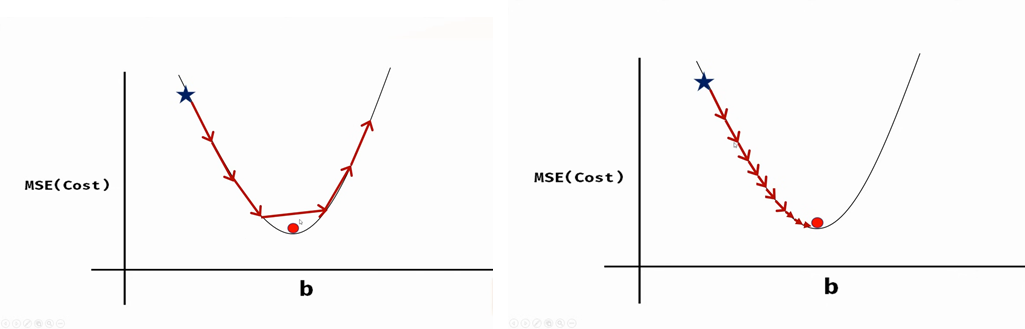

In [3]:
# code credit:codebasics https://codebasics.io/coming-soon

import numpy as np

def gradient_descent(x, y, iterations=100, learning_rate=0.08, verbose=True):
    # iterations and learning_rate are now arguments; the defaults are the supplied values
    m_curr = b_curr = 0
    n = len(x)
    history = []

    for i in range(iterations):
        y_predicted = m_curr * x + b_curr
        cost = (1/n) * sum([val**2 for val in (y-y_predicted)])
        # Record and print the cost with the m and b that produced it, before updating them
        history.append((m_curr, b_curr, cost))
        if verbose:
            print ("m {}, b {}, cost {} iteration {}".format(m_curr,b_curr,cost, i))
        if not np.isfinite(cost) or cost > 1e12:
            break   # the steps are growing without limit, so stop
        md = -(2/n)*sum(x*(y-y_predicted))
        bd = -(2/n)*sum(y-y_predicted)
        m_curr = m_curr - learning_rate * md
        b_curr = b_curr - learning_rate * bd
    final_cost = (1/n) * sum([val**2 for val in (y - (m_curr * x + b_curr))])
    return m_curr, b_curr, final_cost, history

x = np.array([1,2,3,4,5])
y = np.array([5,7,9,11,13])

m, b, final_cost, history = gradient_descent(x,y)

m 0, b 0, cost 89.0 iteration 0
m 4.96, b 1.44, cost 71.10560000000002 iteration 1
m 0.4991999999999983, b 0.26879999999999993, cost 56.8297702400001 iteration 2
m 4.451584000000002, b 1.426176000000001, cost 45.43965675929613 iteration 3
m 0.892231679999997, b 0.5012275199999995, cost 36.35088701894832 iteration 4
m 4.041314713600002, b 1.432759910400001, cost 29.097483330142282 iteration 5
m 1.2008760606719973, b 0.7036872622079998, cost 23.307872849944438 iteration 6
m 3.7095643080294423, b 1.4546767911321612, cost 18.685758762535738 iteration 7
m 1.4424862661541864, b 0.881337636696883, cost 14.994867596913156 iteration 8
m 3.4406683721083144, b 1.4879302070713722, cost 12.046787238456794 iteration 9
m 1.6308855378034224, b 1.0383405553279617, cost 9.691269350698109 iteration 10
m 3.2221235247119777, b 1.5293810083298451, cost 7.8084968312098315 iteration 11
m 1.7770832372205707, b 1.1780607551353204, cost 6.302918117062937 iteration 12
m 3.0439475772474127, b 1.5765710804477953, c

In [4]:
print(f'After 100 iterations at learning rate 0.08: m = {m:.4f}, b = {b:.4f}, cost = {final_cost:.6f}')
print('The data lie exactly on y = 2x + 3, so the lowest possible cost is 0, at m = 2 and b = 3.')
print('Check with a least-squares fit:', np.polyfit(x, y, 1).round(6))

After 100 iterations at learning rate 0.08: m = 2.0405, b = 2.8536, cost = 0.003901
The data lie exactly on y = 2x + 3, so the lowest possible cost is 0, at m = 2 and b = 3.
Check with a least-squares fit: [2. 3.]


## Part 2: changing the iterations and the learning rate
### My check: a grid of iterations and learning rates
I run the same function, without printing every step, for six learning rates and four iteration counts, and record the cost after the final update. A run is marked "diverged" if its cost ends higher than at the start (89), meaning the steps grew instead of shrinking.

In [5]:
def diverged(final_cost, history):
    # The cost ended higher than at the start, or grew past the safety stop
    return (not np.isfinite(final_cost)) or final_cost > history[0][2]

rates = [0.001, 0.01, 0.05, 0.08, 0.085, 0.09]
iteration_counts = [10, 100, 1000, 10000]
grid = {}
for lr in rates:
    row = {}
    for it in iteration_counts:
        m_g, b_g, c_g, h_g = gradient_descent(x, y, iterations=it, learning_rate=lr, verbose=False)
        row[it] = 'diverged' if diverged(c_g, h_g) else f'{c_g:.3g}'
    grid[lr] = row
grid_table = pd.DataFrame(grid).T
grid_table.index.name = 'learning rate'
grid_table.columns = [f'{it} iterations' for it in iteration_counts]
print('Cost after the final update')
print(grid_table.to_string())

Cost after the final update
              10 iterations 100 iterations 1000 iterations 10000 iterations
learning rate                                                              
0.001                  55.5           1.61           0.478          0.00109
0.010                  1.28          0.477         0.00107         1.04e-27
0.050                 0.668          0.031        1.46e-15         3.17e-29
0.080                  9.69         0.0039        1.43e-24         1.03e-29
0.085              diverged       diverged        diverged         diverged
0.090              diverged       diverged        diverged         diverged


In [6]:
for lr in rates:
    m_g, b_g, c_g, h_g = gradient_descent(x, y, iterations=1000, learning_rate=lr, verbose=False)
    if not diverged(c_g, h_g):
        print(f'learning rate {lr}: after 1,000 iterations m = {m_g:.4f}, b = {b_g:.4f}')
    else:
        print(f'learning rate {lr}: diverged; cost after {len(h_g)} iterations {c_g:.3g}')

learning rate 0.001: after 1,000 iterations m = 2.4487, b = 1.3801
learning rate 0.01: after 1,000 iterations m = 2.0213, b = 2.9232
learning rate 0.05: after 1,000 iterations m = 2.0000, b = 3.0000
learning rate 0.08: after 1,000 iterations m = 2.0000, b = 3.0000
learning rate 0.085: diverged; cost after 1000 iterations 4.7e+11
learning rate 0.09: diverged; cost after 97 iterations 1.27e+12


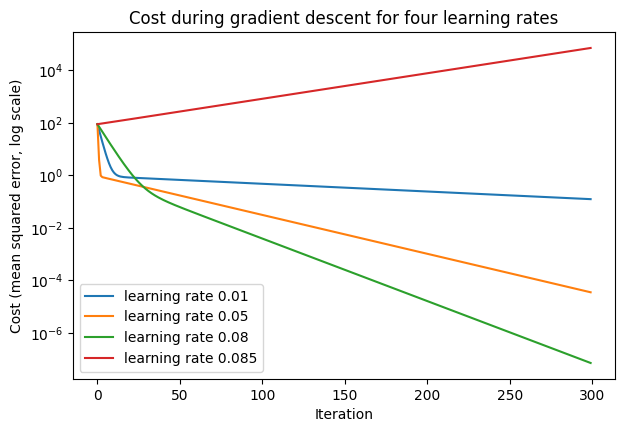

In [7]:
plt.figure(figsize=(7, 4.5))
for lr in [0.01, 0.05, 0.08, 0.085]:
    _, _, _, h = gradient_descent(x, y, iterations=300, learning_rate=lr, verbose=False)
    plt.plot([c for _, _, c in h], label=f'learning rate {lr}')
plt.yscale('log')
plt.xlabel('Iteration')
plt.ylabel('Cost (mean squared error, log scale)')
plt.title('Cost during gradient descent for four learning rates')
plt.legend()
save_figure('01_cost_by_learning_rate.png')
plt.show()

### My check: how few iterations, and when is the learning rate too large?
The supplied notebook says the goal is to reach the minimum cost with the fewest iterations. I count the iterations each learning rate needs to bring the cost below 0.000001, a threshold I chose, then scan learning rates between 0.080 and 0.090 to find where the runs start to diverge. The supplied notebook also warns that a high learning rate may miss the global minimum. The mean squared error of a straight-line fit is convex, with no local minima and one global minimum (Géron, 2025), so a learning rate that is too large cannot settle in a worse minimum; it can only fail to settle. For a cost shaped like a bowl, the eigenvalues of its second-derivative matrix set the scale of the learning rate, and a step that is too large overshoots and goes uphill along the most curved direction (Goodfellow, Bengio and Courville, 2016). From the update rule, each step multiplies the remaining distance to the minimum along a direction by 1 minus the learning rate times the curvature in that direction. When that factor is negative the step overshoots, and once its size passes 1 the steps grow instead of shrinking, which happens when the learning rate passes 2 divided by the steepest curvature (the largest eigenvalue of the cost's second-derivative, or Hessian, matrix). I compute these for this data and compare them with the scan.

In [8]:
def iterations_to_tolerance(x, y, learning_rate, tolerance=1e-6, max_iterations=100000):
    _, _, _, h = gradient_descent(x, y, iterations=max_iterations, learning_rate=learning_rate, verbose=False)
    for i, (_, _, c) in enumerate(h):
        if c < tolerance:
            return i
    return None

tolerance_results = {}
tolerance_rates = [0.001, 0.01, 0.05, 0.07, 0.08, 0.081, 0.082, 0.083, 0.084]
for lr in tolerance_rates:
    n_it = iterations_to_tolerance(x, y, lr)
    tolerance_results[lr] = n_it
    print(f'learning rate {lr}: cost below 0.000001 after', n_it, 'iterations' if n_it is not None else '(not reached in 100,000)')

learning rate 0.001: cost below 0.000001 after 20336 iterations
learning rate 0.01: cost below 0.000001 after 2031 iterations
learning rate 0.05: cost below 0.000001 after 404 iterations
learning rate 0.07: cost below 0.000001 after 288 iterations
learning rate 0.08: cost below 0.000001 after 251 iterations
learning rate 0.081: cost below 0.000001 after 248 iterations
learning rate 0.082: cost below 0.000001 after 245 iterations
learning rate 0.083: cost below 0.000001 after 257 iterations
learning rate 0.084: cost below 0.000001 after 734 iterations


In [9]:
scan = {}
for lr in np.round(np.arange(0.080, 0.0901, 0.001), 3):
    _, _, c_s, h_s = gradient_descent(x, y, iterations=1000, learning_rate=lr, verbose=False)
    scan[float(lr)] = 'diverged' if diverged(c_s, h_s) else f'{c_s:.3g}'
print('Cost after 1,000 iterations:')
for lr, c in scan.items():
    print(f'  learning rate {lr:.3f}: {c}')

n = len(x)
hessian = (2 / n) * np.array([[np.sum(x * x), np.sum(x)], [np.sum(x), n]])
eigenvalues = np.linalg.eigvalsh(hessian)
limit = 2 / eigenvalues.max()
print('Curvature of the cost bowl (eigenvalues):', eigenvalues.round(4))
print('Steepest over flattest curvature:', round(float(eigenvalues.max() / eigenvalues.min()), 1))
print('The steps shrink only for learning rates below', round(float(limit), 4))
for lr in tolerance_rates + [0.085]:
    factors = 1 - lr * eigenvalues
    print(f'learning rate {lr}: factor per step, flattest {factors[0]:.3f}, steepest {factors[1]:.3f}')

Cost after 1,000 iterations:
  learning rate 0.080: 1.43e-24
  learning rate 0.081: 7.15e-25
  learning rate 0.082: 3.56e-25
  learning rate 0.083: 1.78e-25
  learning rate 0.084: 1.28e-09
  learning rate 0.085: diverged
  learning rate 0.086: diverged
  learning rate 0.087: diverged
  learning rate 0.088: diverged
  learning rate 0.089: diverged
  learning rate 0.090: diverged
Curvature of the cost bowl (eigenvalues): [ 0.3381 23.6619]
Steepest over flattest curvature: 70.0
The steps shrink only for learning rates below 0.0845
learning rate 0.001: factor per step, flattest 1.000, steepest 0.976
learning rate 0.01: factor per step, flattest 0.997, steepest 0.763
learning rate 0.05: factor per step, flattest 0.983, steepest -0.183
learning rate 0.07: factor per step, flattest 0.976, steepest -0.656
learning rate 0.08: factor per step, flattest 0.973, steepest -0.893
learning rate 0.081: factor per step, flattest 0.973, steepest -0.917
learning rate 0.082: factor per step, flattest 0.972

### My check: does scaling the input change this?
Géron (2025) warns that gradient descent takes much longer to converge when features have very different scales, because the cost bowl becomes elongated. Here the input x runs from 1 to 5 while the intercept's input is always 1. I standardise x (subtract its mean, divide by its standard deviation), rerun the same function, and convert the result back to the slope and intercept of the original line.

In [10]:
x_scaled = (x - x.mean()) / x.std()
hessian_scaled = (2 / n) * np.array([[np.sum(x_scaled * x_scaled), np.sum(x_scaled)], [np.sum(x_scaled), n]])
eigenvalues_scaled = np.linalg.eigvalsh(hessian_scaled)
print('Curvature after scaling (eigenvalues):', eigenvalues_scaled.round(4))
print('The steps shrink only for learning rates below', round(float(2 / eigenvalues_scaled.max()), 4))
scaled_results = {}
for lr in [0.01, 0.05, 0.08, 0.5, 0.9]:
    n_it = iterations_to_tolerance(x_scaled, y, lr)
    scaled_results[lr] = n_it
    print(f'scaled x, learning rate {lr}: cost below 0.000001 after', n_it, 'iterations')
m_s, b_s, _, _ = gradient_descent(x_scaled, y, iterations=100, learning_rate=0.08, verbose=False)
print(f'Scaled run converted back: m = {m_s / x.std():.4f}, b = {b_s - m_s * x.mean() / x.std():.4f}')

Curvature after scaling (eigenvalues): [2. 2.]
The steps shrink only for learning rates below 1.0
scaled x, learning rate 0.01: cost below 0.000001 after 454 iterations
scaled x, learning rate 0.05: cost below 0.000001 after 87 iterations
scaled x, learning rate 0.08: cost below 0.000001 after 53 iterations
scaled x, learning rate 0.5: cost below 0.000001 after 1 iterations
scaled x, learning rate 0.9: cost below 0.000001 after 42 iterations
Scaled run converted back: m = 2.0000, b = 3.0000


### My check: what if no line fits every point?
The supplied points lie exactly on a line, so the cost can fall to zero. I change the last target from 13 to 18, so that no straight line passes through all five points, and rerun gradient descent at four learning rates for 1,000 iterations. A least-squares fit gives the best line and the lowest possible cost to compare against. The second derivatives of the cost involve only x, not y, so the learning-rate limit should not move.

In [11]:
y_changed = y.copy()
y_changed[-1] = 18
best = np.polyfit(x, y_changed, 1)
lowest_cost = float(np.mean((y_changed - np.polyval(best, x)) ** 2))
print('Least-squares line for the changed data: m =', best.round(4)[0], ', b =', best.round(4)[1], '; lowest possible cost', round(lowest_cost, 4))
changed_results = {}
for lr in [0.05, 0.08, 0.084, 0.085]:
    m_c, b_c, c_c, h_c = gradient_descent(x, y_changed, iterations=1000, learning_rate=lr, verbose=False)
    if diverged(c_c, h_c):
        changed_results[lr] = 'diverged'
        print(f'changed data, learning rate {lr}: diverged; cost after {len(h_c)} iterations {c_c:.3g}')
    else:
        changed_results[lr] = {'m': float(m_c), 'b': float(b_c), 'cost': float(c_c)}
        print(f'changed data, learning rate {lr}: m = {m_c:.4f}, b = {b_c:.4f}, cost = {c_c:.4f}')

Least-squares line for the changed data: m = 3.0 , b = 1.0 ; lowest possible cost 2.0
changed data, learning rate 0.05: m = 3.0000, b = 1.0000, cost = 2.0000
changed data, learning rate 0.08: m = 3.0000, b = 1.0000, cost = 2.0000
changed data, learning rate 0.084: m = 3.0000, b = 1.0000, cost = 2.0000
changed data, learning rate 0.085: diverged; cost after 1000 iterations 6.3e+11


In [12]:
results = {'run_by': 'Anne Dayer (student 39359)',
           'run_at_utc': datetime.now(timezone.utc).isoformat(timespec='minutes'),
           'execution_scope': 'Google Colab', 'packages': versions,
           'supplied_run': {'iterations': 100, 'learning_rate': 0.08, 'm': float(m), 'b': float(b), 'final_cost': float(final_cost)},
           'grid_final_cost': {str(k): v for k, v in grid.items()},
           'iterations_to_tolerance': {str(k): v for k, v in tolerance_results.items()},
           'divergence_scan': scan,
           'learning_rate_limit': float(limit), 'eigenvalues': eigenvalues.tolist(),
           'scaled': {'eigenvalues': eigenvalues_scaled.tolist(), 'iterations_to_tolerance': {str(k): v for k, v in scaled_results.items()}},
           'changed_target': {'best_line': best.tolist(), 'lowest_cost': lowest_cost, 'runs': {str(k): v for k, v in changed_results.items()}}}
(OUT / 'Unit8_results.json').write_text(json.dumps(results, indent=2), encoding='utf-8')
print('Outputs saved to', OUT)

Outputs saved to /content/Unit8_ePortfolio_Exports


## Interpretation and limitations
Raising the learning rate shortened the descent only up to a point. Every rate up to 0.084 reached the line y = 2x + 3 given enough iterations, but among the rates I tried the fewest iterations came at 0.082, not at the largest stable rate: at 0.084 the steps overshot back and forth across the steepest direction of the cost bowl, and from 0.085 the cost grew instead of falling. The supplied 0.08 therefore sits just under the limit computed from the curvature, which also explains why it overshoots at first: after 10 iterations it leaves a higher cost than 0.05 does. The steepest direction sets the limit, while the flattest, about 70 times flatter, sets how slowly the last part of the descent goes; Goodfellow, Bengio and Courville (2016) describe the same problem, where the learning rate must be shrunk to compensate for stronger curvature. Standardising x made the bowl round, so a larger learning rate became safe and fewer iterations were needed at the same rate, as Géron (2025) advises. The cost is convex, so there was no other minimum to miss: 0.085 failed because it exceeded the limit. Changing one target showed what the data control: the stable runs settled on the least-squares line with a cost above zero, while the learning-rate limit did not move, because it depends only on x. A cost that stops falling above zero can therefore mean that no line fits the data, not that the optimiser failed. All of this is training data: reducing the cost is not the same as performing well on unseen data (Goodfellow, Bengio and Courville, 2016), and the limit found here belongs to these inputs.

## Sources
- Géron, A. (2025) *Hands-On Machine Learning with Scikit-Learn and PyTorch*. Santa Rosa: O’Reilly.
- Goodfellow, I., Bengio, Y. and Courville, A. (2016) *Deep Learning*. Cambridge, MA: MIT Press. Available at: https://www.deeplearningbook.org/ (Accessed: 3 November 2026).
- Mayo, M. (2017) ‘Neural network foundations, explained: updating weights with gradient descent & backpropagation’, *KDnuggets*, 25 October. Available at: https://www.kdnuggets.com/2017/10/neural-network-foundations-explained-gradient-descent.html (Accessed: 20 October 2026).

Supplied materials: University of Essex Unit 8 e-Portfolio brief and the notebook gradient_descent_cost_function.ipynb (code credit: codebasics).